# Naive_Bayes

In [ ]:
# step 1:import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt  
import seaborn as sns

In [4]:
pip install sklearn

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [11]:
# step 2:Load the dataset
df = pd.read_csv(r"C:\Users\asusvivobook\Desktop\FSDS\ML Practicals\Navie Bayes\Navie_Bayes\Naive-Bayes-Classification-Data.csv")

In [12]:
df.head()

,glucose,bloodpressure,diabetes
0,40,85,0
1,40,92,0
2,45,63,1
3,45,80,0
4,40,73,1


In [13]:
df.shape

(995, 3)

In [14]:
df.info

<bound method DataFrame.info of      glucose  bloodpressure  diabetes
0         40             85         0
1         40             92         0
2         45             63         1
3         45             80         0
4         40             73         1
..       ...            ...       ...
990       45             87         0
991       40             83         0
992       40             83         0
993       40             60         1
994       45             82         0

[995 rows x 3 columns]>

In [15]:
df.columns

Index(['glucose', 'bloodpressure', 'diabetes'], dtype='str')

In [16]:
df.isnull().sum()

glucose          0
bloodpressure    0
diabetes         0
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(820)

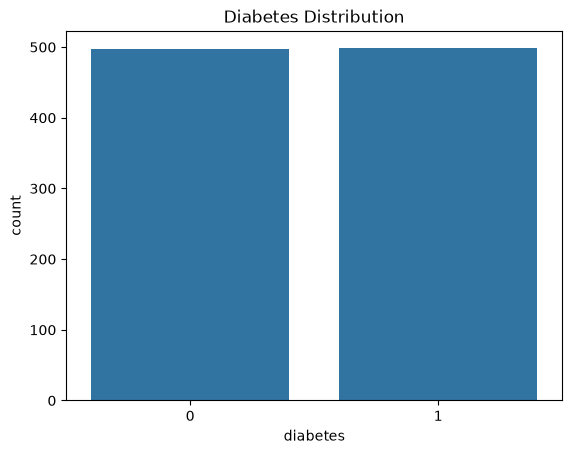

In [18]:
sns.countplot(x="diabetes", data=df)
plt.title("Diabetes Distribution")
plt.show()

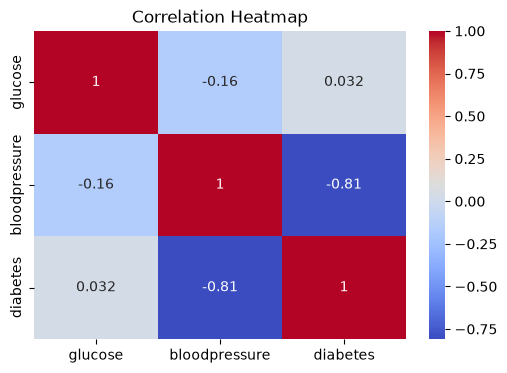

In [19]:
# check the relationship between the features
plt.figure(figsize=(6, 4))

sns.heatmap(df.corr(), annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

In [20]:
# separate x and y
X = df.drop("diabetes", axis=1)

y = df["diabetes"]

In [21]:
from sklearn.model_selection import train_test_split

print("Working!")

Working!


In [22]:
# split the data for testing and training
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [23]:
# create the Naive bayes model
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [24]:
model = GaussianNB()

In [25]:
# train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [26]:
# make predictions
y_pred = model.predict(X_test)

print(y_pred)

[0 1 0 0 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 0 1 1 0 1 0 1 0 0 1 0 0 0 0 1 1 0 0
 0 0 0 1 0 0 0 0 1 1 0 1 0 1 1 0 0 1 0 0 1 1 1 0 0 0 1 0 1 0 0 1 0 1 0 1 1
 1 1 1 1 0 0 1 1 1 1 0 0 0 0 0 1 1 1 0 0 1 1 0 1 0 1 0 1 1 1 0 1 0 1 1 1 1
 1 0 0 1 1 0 1 0 1 0 1 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 0 1 1 1 0 1 0 0 1 1
 0 0 0 0 1 1 1 0 1 0 0 0 1 1 0 1 0 1 0 0 0 0 0 0 0 1 1 0 0 0 1 1 0 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 0 0 1]


In [27]:
# check the accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 0.9095477386934674
Accuracy Percentage: 90.95477386934674


In [28]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[90  9]
 [ 9 91]]


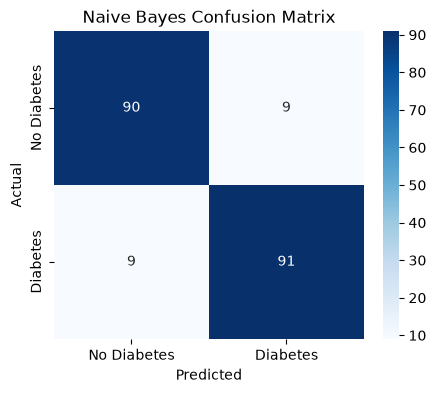

In [29]:
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes Confusion Matrix")

plt.show()

In [30]:
# classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.91      0.91        99
           1       0.91      0.91      0.91       100

    accuracy                           0.91       199
   macro avg       0.91      0.91      0.91       199
weighted avg       0.91      0.91      0.91       199



In [31]:
# test with new patient data
new_patient = [[120, 80]]

prediction = model.predict(new_patient)

print("Prediction:", prediction[0])

Prediction: 1


c:\Users\asusvivobook\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


In [38]:
# save the trained model
import joblib

joblib.dump(model,"naive_bayes_model.pkl")

print("Model saved successfully!")

Model saved successfully!
